[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/03-math/07_calculus.ipynb)

*Math for Data Science & ML · Notebook 7 of 10*

# Calculus: Derivatives & Integrals

The math of change. Slopes of curves, the derivative rules, finding minimums and maximums, Newton's method, and areas under curves.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A derivative is a speedometer: how fast the output changes when you nudge the input.

**What interviewers really test here:** Chain rule, partial derivatives, and how they power backpropagation.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Rate of change and the idea of a limit *(Basics)*
- [ ] 2. Derivative rules *(Basics)*
- [ ] 3. Limits by hand *(Basics)*
- [ ] 4. The derivative from first principles *(Basics)*
- [ ] 5. Finding maximums and minimums *(Core)*
- [ ] 6. Integrals: adding up tiny pieces *(Core)*
- [ ] 7. Chain and product rule, worked *(Core)*
- [ ] 8. Optimisation problems, worked *(Core)*
- [ ] 9. Derivatives of real data *(Advanced)*
- [ ] 10. Approximating with lines: Taylor and Newton *(Advanced)*
- [ ] 11. Integrals, worked *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Limits and continuity

lim\_{x→a} f(x) = L means f(x) gets arbitrarily close to L as x gets close to a (from both sides). f is **continuous** at a if lim\_{x→a} f(x) = f(a) — no jumps or holes. Famous limits: lim (sin x)/x = 1 as x → 0; lim (1 + 1/n)ⁿ = e as n → ∞.

### The derivative

**f′(a) = lim\_{h→0} (f(a + h) − f(a)) / h** — the slope of the tangent line, the instantaneous rate of change. Notation: f′(x), dy/dx, df/dx. A function with a corner (|x| at 0, ReLU at 0) is continuous but not differentiable there.



| Rule | Formula |
| --- | --- |
| Power | d/dx xⁿ = nxⁿ⁻¹ |
| Exponential | d/dx eˣ = eˣ, d/dx aˣ = aˣ ln a |
| Logarithm | d/dx ln x = 1/x |
| Trig | sin′ = cos, cos′ = −sin |
| Linearity | (af + bg)′ = af′ + bg′ |
| Product | (fg)′ = f′g + fg′ |
| Quotient | (f/g)′ = (f′g − fg′)/g² |
| Chain | (f∘g)′(x) = f′(g(x))·g′(x) |

### Using derivatives

- **Tangent line** at a: y = f(a) + f′(a)(x − a) — the best straight-line approximation near a (linearisation).
- **Monotonicity**: f′ &gt; 0 increasing, f′ &lt; 0 decreasing.
- **Critical points**: f′ = 0 (or undefined). Second-derivative test: f″ &gt; 0 local min, f″ &lt; 0 local max, f″ = 0 inconclusive.
- **Convex** functions (f″ ≥ 0 everywhere) have no false valleys: any local minimum is global — why convex losses (MSE for linear regression, log-loss for logistic regression) are easy to train.
- **Taylor series**: f(x) ≈ f(a) + f′(a)(x − a) + f″(a)(x − a)²/2 + … — the basis of Newton's method.
- **Newton's method** for roots: xₙ₊₁ = xₙ − f(xₙ)/f′(xₙ); for minimums: xₙ₊₁ = xₙ − f′(xₙ)/f″(xₙ).

### Integrals

∫ₐᵇ f(x) dx = lim Σ f(xᵢ)Δx (Riemann sum) — signed area under the curve. The indefinite integral ∫ f dx = F(x) + C where F′ = f.



**Fundamental Theorem of Calculus**: d/dx ∫ₐˣ f(t) dt = f(x) and ∫ₐᵇ f dx = F(b) − F(a).



|   |   |
| --- | --- |
| ∫ xⁿ dx = xⁿ⁺¹/(n + 1) + C (n ≠ −1) | ∫ 1/x dx = ln\|x\| + C |
| ∫ eˣ dx = eˣ + C | average value = (1/(b − a)) ∫ₐᵇ f dx |



Numerical integration: left/right/midpoint rectangles (error ∝ Δx or Δx²), trapezoid (∝ Δx²), Simpson's rule (∝ Δx⁴).

---
# Part 2: Lessons, step by step

## Lesson 1: Rate of change and the idea of a limit

*Level: Basics*

Calculus is the math of **change**. Speed is change in distance per second; the slope of a line is change in y per change in x. But a **curve** has a different steepness at every point. How steep is y = x² exactly at x = 3?



Idea: take a second point a tiny step h away and compute the slope between them (a **secant**): (f(3 + h) − f(3))/h. Make h smaller and smaller:



| h | slope |
| --- | --- |
| 0.1 | 6.1 |
| 0.01 | 6.01 |
| 0.001 | 6.001 |



The numbers home in on 6. That target is a **limit**, and the slope at a single point is the **derivative**: f′(3) = 6.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

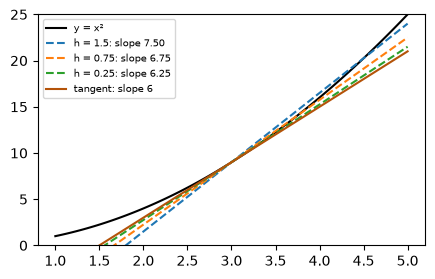

In [2]:
def secant_to_tangent():
    x = np.linspace(1, 5, 100)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(x, x ** 2, color="black", label="y = x²")
    for h in [1.5, 0.75, 0.25]:
        m = ((3 + h) ** 2 - 9) / h
        ax.plot(x, 9 + m * (x - 3), "--", label=f"h = {h}: slope {m:.2f}")
    ax.plot(x, 9 + 6 * (x - 3), color="#b45309", label="tangent: slope 6")
    ax.set_ylim(0, 25)
    ax.legend(fontsize=7)


secant_to_tangent()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2). Try one now, or carry on and do them in Part 3.

## Lesson 2: Derivative rules

*Level: Basics*

Nobody computes limits every time. A few rules cover almost everything:



| Rule | Formula | Example |
| --- | --- | --- |
| Constant | (c)′ = 0 | (7)′ = 0 |
| Power | (xⁿ)′ = n·xⁿ⁻¹ | (x³)′ = 3x² |
| Sum | (f + g)′ = f′ + g′ | (x² + x)′ = 2x + 1 |
| Product | (fg)′ = f′g + fg′ | (x·eˣ)′ = eˣ + x·eˣ |
| Chain | f(g(x))′ = f′(g(x))·g′(x) | ((2x + 1)³)′ = 3(2x + 1)²·2 |
| Exponential, log | (eˣ)′ = eˣ, (ln x)′ = 1/x |   |



The **chain rule** is the most important for ML: a neural network is functions inside functions, and **backpropagation is just the chain rule applied layer by layer**.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

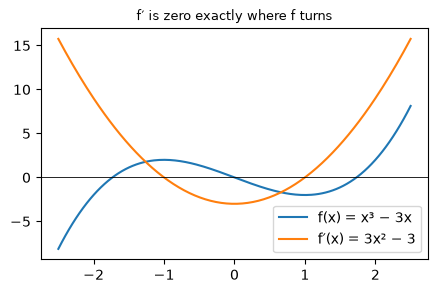

In [3]:
def function_and_derivative():
    x = np.linspace(-2.5, 2.5, 200)
    p = [1, 0, -3, 0]
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(x, np.polyval(p, x), label="f(x) = x³ − 3x")
    ax.plot(x, np.polyval(np.polyder(p), x), label="f′(x) = 3x² − 3")
    ax.axhline(0, color="black", linewidth=0.6)
    ax.legend()
    ax.set_title("f′ is zero exactly where f turns", fontsize=9)


function_and_derivative()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q10](#q10), [Q11](#q11), [Q12](#q12), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 3: Limits by hand

*Level: Basics*

A limit asks: **what value does f approach as x gets close to a point?** It doesn't matter what happens exactly at that point.



#### Example 1: a hole in a graph



f(x) = (x² − 1) / (x − 1). At x = 1 this is 0/0, undefined. Try nearby values:



| x | 1.1 | 1.01 | 1.001 |
| --- | --- | --- | --- |
| f(x) | 2.1 | 2.01 | 2.001 |



The limit is **2**. Algebra agrees: (x² − 1) = (x − 1)(x + 1), so f(x) = x + 1 for x ≠ 1.



#### Example 2: sin(x) / x near 0



| x | 1 | 0.1 | 0.01 |
| --- | --- | --- | --- |
| sin(x) / x | 0.84147 | 0.99833 | 0.99998 |



The limit is **1**.



#### Why do we care?



A slope needs two points, but "the slope at a point" has only one. A limit solves this: make the two points closer and closer and see what the slope approaches. That's a derivative.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

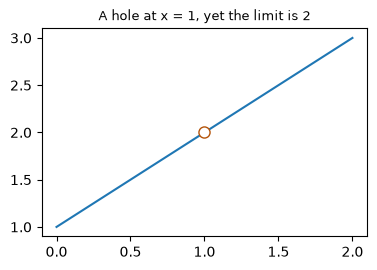

In [4]:
def limit_tables():
    near_one = {x: round((x ** 2 - 1) / (x - 1), 4) for x in [1.1, 1.01, 1.001, 0.999]}
    near_zero = {x: round(math.sin(x) / x, 5) for x in [1, 0.1, 0.01]}
    xs = np.linspace(0, 2, 101)
    xs = xs[np.abs(xs - 1) > 1e-9]
    fig, ax = plt.subplots(figsize=(4.2, 2.7))
    ax.plot(xs, (xs ** 2 - 1) / (xs - 1))
    ax.plot(1, 2, "o", markerfacecolor="white", color="#b45309", markersize=8)
    ax.set_title("A hole at x = 1, yet the limit is 2", fontsize=9)


limit_tables()

**✏️ Your turn:** you now have what you need for [Q1](#q1). Try one now, or carry on and do them in Part 3.

## Lesson 4: The derivative from first principles

*Level: Basics*

Find the derivative of f(x) = x² using the definition: the limit of (f(x + h) − f(x)) / h as h → 0.



1. (x + h)² − x² = x² + 2xh + h² − x² = 2xh + h²
2. Divide by h: 2x + h
3. Let h → 0: **2x**



So at x = 3 the slope is 6, which matches the shrinking-secant table you saw earlier.



#### Now use the rules



f(x) = 3x² + 2x − 5, term by term:



| Term | Derivative | Rule |
| --- | --- | --- |
| 3x² | 6x | bring the power down, reduce it by 1 |
| 2x | 2 | slope of a line |
| −5 | 0 | constants don't change |



f′(x) = 6x + 2, so f′(1) = 8. At x = 1, a tiny increase in x raises f about 8 times as much.



**What f′ tells you:** positive means rising, negative means falling, zero means flat, and a larger size means steeper.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [5]:
def first_principles():
    x = 3.0
    estimates = {h: round(((x + h) ** 2 - x ** 2) / h, 4) for h in [1, 0.1, 0.01, 0.001]}
    derivative = np.polyder([3, 2, -5])
    at_one = np.polyval(derivative, 1)
    h = 0.0001
    numeric_check = round(((3 * (1 + h) ** 2 + 2 * (1 + h) - 5) - (3 + 2 - 5)) / h, 3)


first_principles()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q9](#q9), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 5: Finding maximums and minimums

*Level: Core*

At the top of a hill or the bottom of a valley the curve is momentarily flat: **f′(x) = 0**. These are **critical points**.



The **second derivative** f″ (the derivative of the derivative) measures curvature and tells them apart:



- f″ &gt; 0: curve bends up like a cup → **minimum**
- f″ &lt; 0: bends down like a cap → **maximum**



Training an ML model **is** finding the minimum of a loss function. With one weight you could solve f′ = 0 by hand; with millions you follow the slope downhill step by step — gradient descent (next topic). **Newton's method** uses f′ (and f″) to jump towards roots or minimums very fast.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

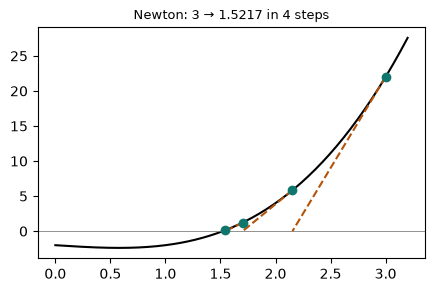

In [6]:
def newton_demo():
    f = lambda x: x ** 3 - x - 2
    df = lambda x: 3 * x ** 2 - 1
    x = 3.0
    steps = [x]
    for _ in range(4):
        x = x - f(x) / df(x)
        steps.append(x)
    xs = np.linspace(0, 3.2, 200)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(xs, f(xs), color="black")
    ax.axhline(0, color="gray", linewidth=0.6)
    for a, b in zip(steps, steps[1:]):
        ax.plot([a, b], [f(a), 0], "--", color="#b45309")
        ax.plot(a, f(a), "o", color="#0f766e")
    ax.set_title(f"Newton: 3 → {steps[-1]:.4f} in 4 steps", fontsize=9)


newton_demo()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q14](#q14), [Q5](#q5), [Q16](#q16), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 6: Integrals: adding up tiny pieces

*Level: Core*

The **integral** ∫ₐᵇ f(x) dx is the **area under the curve** between a and b. Estimate it by slicing into thin rectangles (a **Riemann sum**) or trapezoids; thinner slices give better answers.



The **Fundamental Theorem of Calculus** connects the two halves of calculus: integration undoes differentiation. If F′ = f, then ∫ₐᵇ f dx = F(b) − F(a). For powers: ∫ xⁿ dx = xⁿ⁺¹/(n + 1).



In data science, integrals give probabilities (area under a probability curve), expected values, and the AUC of an ROC curve.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

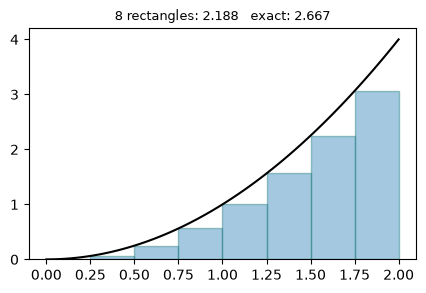

In [7]:
def riemann_demo():
    a, b, n = 0, 2, 8
    dx = (b - a) / n
    lefts = a + dx * np.arange(n)
    estimate = (lefts ** 2).sum() * dx
    exact = (b ** 3 - a ** 3) / 3
    xs = np.linspace(a, b, 100)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(xs, xs ** 2, color="black")
    ax.bar(lefts, lefts ** 2, width=dx, align="edge", alpha=0.4, edgecolor="#0f766e")
    ax.set_title(f"8 rectangles: {estimate:.3f}   exact: {exact:.3f}", fontsize=9)


riemann_demo()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q7](#q7), [Q8](#q8), [Q17](#q17), [Q18](#q18), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 7: Chain and product rule, worked

*Level: Core*

#### Chain rule: outside times inside



f(x) = (3x + 1)².



1. Outside: something² has derivative 2 × something.
2. Inside: 3x + 1 has derivative 3.
3. Multiply: 2(3x + 1) × 3 = **18x + 6**.



**Check by expanding:** 9x² + 6x + 1 has derivative 18x + 6 ✓.



| Function | Outside | Inside | Derivative |
| --- | --- | --- | --- |
| e^(2x) | eᵘ | 2x | 2e^(2x) |
| e^(−x²) | eᵘ | −x² | −2x·e^(−x²) |
| ln(x² + 1) | ln u | x² + 1 | 2x / (x² + 1) |
| (y − wx)² | u² | y − wx (with respect to w) | −2x(y − wx) |



The last row is exactly the gradient used to train linear regression.



#### Product rule



(x²·eˣ)′ = 2x·eˣ + x²·eˣ: first′ × second + first × second′.



**Common mistake:** forgetting the inside derivative, as in writing e^(2x) instead of 2e^(2x).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [8]:
def chain_checks():
    def numeric(f, x, h=1e-6):
        return (f(x + h) - f(x - h)) / (2 * h)

    x = 1.5
    outer_inner = (numeric(lambda t: (3 * t + 1) ** 2, x), 18 * x + 6)
    exp_case = (numeric(lambda t: math.exp(-t ** 2), x), -2 * x * math.exp(-x ** 2))
    log_case = (numeric(lambda t: math.log(t ** 2 + 1), x), 2 * x / (x ** 2 + 1))
    w, y, xi = 2.0, 10.0, 3.0
    loss_case = (numeric(lambda t: (y - t * xi) ** 2, w), -2 * xi * (y - w * xi))


chain_checks()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. numeric() returns 32.99999999484271
2. numeric() returns -0.3161976736554273
3. numeric() returns 0.9230769230095248
4. numeric() returns -23.99999999891378
5. chain\_checks() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q10](#q10), [Q12](#q12), [Q2](#q2). Try one now, or carry on and do them in Part 3.

## Lesson 8: Optimisation problems, worked

*Level: Core*

#### The biggest field



You have 40 m of fence for a rectangle. What's the largest area?



1. **Variable:** width x, so height = 20 − x.
2. **Goal:** A(x) = x(20 − x) = 20x − x².
3. **Slope = 0:** A′ = 20 − 2x = 0, so x = 10.
4. **Maximum?** A″ = −2 is negative, so yes.



A 10 × 10 square gives **100 m²**.



#### Why is the mean the "best single guess"?



Choose a number c to minimise the total squared error Σ(xᵢ − c)². The derivative is −2Σ(xᵢ − c). Setting it to 0 gives Σxᵢ = n·c, so **c = the mean**.



Minimise absolute error instead, and the answer is the **median**. So the choice of loss decides what a model predicts. This explains why MSE models predict averages and why MAE resists outliers.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

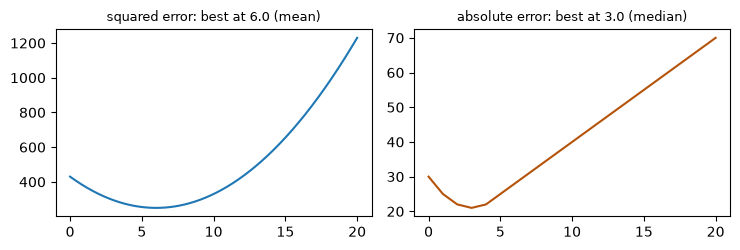

In [9]:
def best_guess():
    x = np.array([1.0, 2, 3, 4, 20])
    candidates = np.linspace(0, 20, 401)
    squared = ((x[:, None] - candidates) ** 2).sum(axis=0)
    absolute = np.abs(x[:, None] - candidates).sum(axis=0)
    best_squared = candidates[squared.argmin()]
    best_absolute = candidates[absolute.argmin()]
    mean_median = (x.mean(), np.median(x))
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.6))
    axes[0].plot(candidates, squared)
    axes[0].set_title(f"squared error: best at {best_squared:.1f} (mean)", fontsize=9)
    axes[1].plot(candidates, absolute, color="#b45309")
    axes[1].set_title(f"absolute error: best at {best_absolute:.1f} (median)", fontsize=9)
    fig.tight_layout()


best_guess()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q14](#q14), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 9: Derivatives of real data

*Level: Advanced*

Real measurements come as samples, not formulas. Derivatives become **differences**: speed ≈ (next position − previous position)/(2·dt) — `np.gradient`. Integrals become sums — the trapezoid rule.



The same numerical tricks let you **check** hand-derived gradients in ML code: compare your formula against (f(x + h) − f(x − h))/2h. This "gradient check" catches most backprop bugs.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

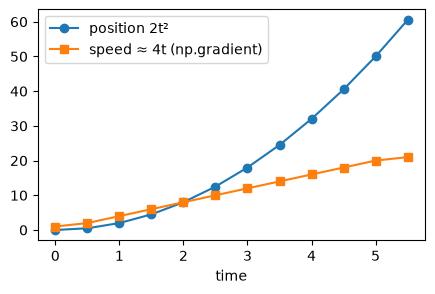

In [10]:
def data_derivative():
    t = np.arange(0, 6, 0.5)
    position = 2 * t ** 2
    speed = np.gradient(position, 0.5)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(t, position, "o-", label="position 2t²")
    ax.plot(t, speed, "s-", label="speed ≈ 4t (np.gradient)")
    ax.set_xlabel("time")
    ax.legend()


data_derivative()

**✏️ Your turn:** you now have what you need for [Q19](#q19), [Q2](#q2), [Q1](#q1). Try one now, or carry on and do them in Part 3.

## Lesson 10: Approximating with lines: Taylor and Newton

*Level: Advanced*

#### Near a point, a curve looks straight



f(x) ≈ f(a) + f′(a)(x − a). Estimate √4.1 using a = 4, where √4 = 2 and the slope 1/(2√4) = 1/4:



√4.1 ≈ 2 + 0.25 × 0.1 = **2.025**. The true value is 2.02485, so it's very close.



**This is why gradient descent works:** for small steps, the slope predicts the change in the loss, and that's why steps must stay small.



#### Adding terms improves it



eˣ = 1 + x + x²/2! + x³/3! + … At x = 1: 1 + 1 + 0.5 + 0.1667 + 0.0417 = 2.7083. The true e is 2.7183.



#### Newton's method by hand



Find √2, a root of x² − 2. The update is x − (x² − 2)/(2x):



| Step | x |
| --- | --- |
| Start | 1 |
| 1 | 1.5 |
| 2 | 1.41667 |
| 3 | 1.41422 (true: 1.41421) |



Correct digits roughly double each step.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

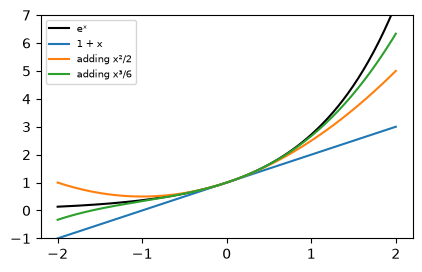

In [11]:
def taylor_demo():
    approx = 2 + 0.25 * 0.1
    true_value = math.sqrt(4.1)
    newton = [1.0]
    for _ in range(3):
        x = newton[-1]
        newton.append(x - (x ** 2 - 2) / (2 * x))
    xs = np.linspace(-2, 2, 200)
    fig, ax = plt.subplots(figsize=(4.8, 2.9))
    ax.plot(xs, np.exp(xs), color="black", label="eˣ")
    ax.plot(xs, 1 + xs, label="1 + x")
    ax.plot(xs, 1 + xs + xs ** 2 / 2, label="adding x²/2")
    ax.plot(xs, 1 + xs + xs ** 2 / 2 + xs ** 3 / 6, label="adding x³/6")
    ax.set_ylim(-1, 7)
    ax.legend(fontsize=7)


taylor_demo()

**✏️ Your turn:** you now have what you need for [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 11: Integrals, worked

*Level: Advanced*

#### Rectangles approach the exact area



Area under x² from 0 to 2, using left rectangles:



| Rectangles | 4 | 8 | 100 | 1000 | Exact |
| --- | --- | --- | --- | --- | --- |
| Estimate | 1.75 | 2.1875 | 2.6268 | 2.6627 | 2.6667 |



#### The exact answer in two lines



An antiderivative of x² is x³/3 (its derivative gives x² back). So the area = 2³/3 − 0³/3 = 8/3 = 2.6667.



**Why does this work?** As you widen the region by a tiny dx, the area grows by height × dx. So the area's rate of growth is the height, f(x). Finding the area means undoing a derivative.



| Integral | Result |
| --- | --- |
| ∫ x³ dx | x⁴/4 + C |
| ∫ (2x + 1) dx | x² + x + C |
| ∫ eˣ dx | eˣ + C |
| ∫ 1/x dx | ln\|x\| + C |



**Where it's used:** a probability is an area under a density. Expected value is ∫ x·f(x) dx. ROC AUC is an area, computed with the trapezoid rule.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

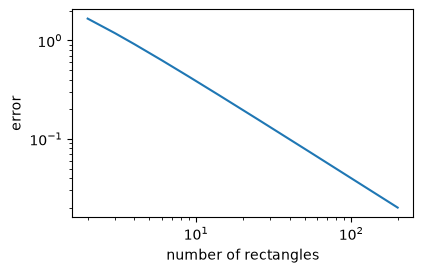

In [12]:
def rectangles_converge():
    def left_sum(n):
        dx = 2 / n
        return float((np.arange(n) * dx) ** 2 @ np.full(n, dx))

    estimates = {n: round(left_sum(n), 4) for n in [4, 8, 100, 1000]}
    antiderivative = np.polyint([1, 0, 0])
    exact = np.polyval(antiderivative, 2) - np.polyval(antiderivative, 0)
    sizes = np.arange(2, 200)
    errors = [exact - left_sum(int(n)) for n in sizes]
    fig, ax = plt.subplots(figsize=(4.4, 2.7))
    ax.loglog(sizes, errors)
    ax.set_xlabel("number of rectangles")
    ax.set_ylabel("error")


rectangles_converge()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. left\_sum() returns 1.75
2. left\_sum() returns 2.1875
3. left\_sum() returns 2.6268000000000002
4. left\_sum() returns 2.662668
5. left\_sum() returns 1.0
6. left\_sum() returns 1.4814814814814814
7. left\_sum() returns 1.75
8. left\_sum() returns 1.9200000000000006
9. left\_sum() returns 2.0370370370370368
10. left\_sum() returns 2.1224489795918364
11. left\_sum() returns 2.1875
12. left\_sum() returns 2.238683127572016
13. left\_sum() returns 2.2800000000000002
14. left\_sum() returns 2.31404958677686
15. left\_sum() returns 2.3425925925925926
16. left\_sum() returns 2.3668639053254443
17. left\_sum() returns 2.387755102040816
18. left\_sum() returns 2.405925925925926
19. left\_sum() returns 2.421875
20. left\_sum() returns 2.43598615916955
21. left\_sum() returns 2.4485596707818926

</details>


**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q8](#q8), [Q17](#q17), [Q18](#q18), [Q20](#q20), [Q7](#q7), [Q19](#q19). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Derivative From the Definition

🟢 Warm-up · *Shrinking the secant*

For f(x) = x², return the slope estimates (f(a + h) − f(a))/h for h = 0.1, 0.01 and 0.001, rounded to 4 decimals. Watch them approach 2a.

**Examples**

- `a = 3` → `[6.1, 6.01, 6.001]`
- `a = 0` → `[0.1, 0.01, 0.001]`
- `a = -1` → `[-1.9, -1.99, -1.999]`

In [ ]:
def secant_slopes(a):
    """
    For f(x) = x², return the slope estimates (f(a + h) − f(a))/h for h = 0.1,
    0.01 and 0.001, rounded to 4 decimals. Watch them approach 2a.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(secant_slopes, [
    ((3,), [6.1, 6.01, 6.001]),
    ((0,), [0.1, 0.01, 0.001]),
    ((-1,), [-1.9, -1.99, -1.999]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop over the three h values.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

All three at once with an array of h values.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** A loop over the three h values.

```python
def secant_slopes(a):
    out = []
    for h in [0.1, 0.01, 0.001]:
        rise = (a + h) ** 2 - a ** 2
        out.append(round(rise / h, 4))
    return out
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** All three at once with an array of h values.

```python
def secant_slopes(a):
    h = np.array([0.1, 0.01, 0.001])
    return (((a + h) ** 2 - a ** 2) / h).round(4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop over the three h values. That costs O(1) time and O(1) space."

"I can do better: All three at once with an array of h values. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/derivative-from-the-definition)

<a id="q2"></a>
### Q2. Derivative of sin x

🟢 Warm-up · *Numerical vs exact*

Return the derivative of sin at x, rounded to 4 decimals.

**Examples**

- `x = 1.0` → `0.5403`
- `x = 0` → `1.0`
- `x = 2` → `-0.4161`

In [ ]:
def dsin(x):
    """
    Return the derivative of sin at x, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dsin, [
    ((1.0,), 0.5403),
    ((0,), 1.0),
    ((2,), -0.4161),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Central difference (sin(x + h) − sin(x − h)) / 2h with a tiny h.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Use the rule: d/dx sin x = cos x.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Central difference (sin(x + h) − sin(x − h)) / 2h with a tiny h.

```python
def dsin(x):
    h = 1e-5
    return round((math.sin(x + h) - math.sin(x - h)) / (2 * h), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Use the rule: d/dx sin x = cos x.

```python
def dsin(x):
    return round(math.cos(x), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Central difference (sin(x + h) − sin(x − h)) / 2h with a tiny h. That costs O(1) time and O(1) space."

"I can do better: Use the rule: d/dx sin x = cos x. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/derivative-of-sin-x)

<a id="q3"></a>
### Q3. Power Rule for Polynomials

🟢 Warm-up · *d/dx xⁿ = n·xⁿ⁻¹*

Return the derivative's coefficients (highest power first). [3, 0, -2, 5] = 3x³ − 2x + 5 → [9, 0, -2].

**Examples**

- `p = [3, 0, -2, 5]` → `[9, 0, -2]`
- `p = [1, 0, 0, 0, 0]` → `[4, 0, 0, 0]`
- `p = [2, 5]` → `[2]`

In [ ]:
def derivative(p):
    """
    Return the derivative's coefficients (highest power first). [3, 0, -2, 5] =
    3x³ − 2x + 5 → [9, 0, -2].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(derivative, [
    (([3, 0, -2, 5],), [9, 0, -2]),
    (([1, 0, 0, 0, 0],), [4, 0, 0, 0]),
    (([2, 5],), [2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Each term c·xᵏ becomes k·c·xᵏ⁻¹; the constant disappears.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polyder(p)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Each term c·xᵏ becomes k·c·xᵏ⁻¹; the constant disappears.

```python
def derivative(p):
    n = len(p) - 1
    if n == 0:
        return [0]
    out = []
    for i, c in enumerate(p[:-1]):
        power = n - i
        out.append(c * power)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.polyder(p)`.

```python
def derivative(p):
    return np.polyder(p)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Each term c·xᵏ becomes k·c·xᵏ⁻¹; the constant disappears. That costs O(n) time and O(n) space."

"I can do better: `np.polyder(p)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/power-rule-for-polynomials)

<a id="q4"></a>
### Q4. Slope of a Curve at a Point

🟢 Warm-up · *f′(a)*

Return the derivative of the polynomial p at x = a.

**Examples**

- `p = [1, -3, 2], a = 4` → `5`
- `p = [2, 0, 0, -1], a = -1` → `6`
- `p = [5, 1], a = 100` → `5`

In [ ]:
def slope_at(p, a):
    """
    Return the derivative of the polynomial p at x = a.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(slope_at, [
    (([1, -3, 2], 4), 5),
    (([2, 0, 0, -1], -1), 6),
    (([5, 1], 100), 5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Power rule by hand, then substitute a.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polyval(np.polyder(p), a)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Power rule by hand, then substitute a.

```python
def slope_at(p, a):
    n = len(p) - 1
    total = 0
    for i, c in enumerate(p[:-1]):
        k = n - i
        total += c * k * a ** (k - 1)
    return total
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.polyval(np.polyder(p), a)`.

```python
def slope_at(p, a):
    return np.polyval(np.polyder(p), a)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Power rule by hand, then substitute a. That costs O(n) time and O(n) space."

"I can do better: `np.polyval(np.polyder(p), a)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/slope-of-a-curve-at-a-point)

<a id="q5"></a>
### Q5. Second Derivative

🟢 Warm-up · *Curvature*

Return the coefficients of f″ for polynomial p.

**Examples**

- `p = [1, 2, 3, 4]` → `[6, 4]`
- `p = [5, 0, 0]` → `[10]`

In [ ]:
def second_derivative(p):
    """
    Return the coefficients of f″ for polynomial p.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(second_derivative, [
    (([1, 2, 3, 4],), [6, 4]),
    (([5, 0, 0],), [10]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Apply the power rule twice.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polyder(p, 2)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Apply the power rule twice.

```python
def second_derivative(p):
    for _ in range(2):
        n = len(p) - 1
        p = [c * (n - i) for i, c in enumerate(p[:-1])]
    return p
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.polyder(p, 2)`.

```python
def second_derivative(p):
    return np.polyder(p, 2)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Apply the power rule twice. That costs O(n) time and O(n) space."

"I can do better: `np.polyder(p, 2)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/second-derivative)

<a id="q6"></a>
### Q6. Area by Rectangles

🟢 Warm-up · *Left Riemann sum*

Estimate the area under f(x) = x² from a to b with n left-endpoint rectangles, rounded to 4 decimals.

**Examples**

- `a = 0, b = 2, n = 4` → `1.75`
- `a = 0, b = 3, n = 6` → `6.875`
- `a = 1, b = 2, n = 10` → `2.185`

In [ ]:
def left_sum(a, b, n):
    """
    Estimate the area under f(x) = x² from a to b with n left-endpoint
    rectangles, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(left_sum, [
    ((0, 2, 4), 1.75),
    ((0, 3, 6), 6.875),
    ((1, 2, 10), 2.185),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over the rectangles: width × height at the left edge.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Make all left edges with `np.arange` and sum.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop over the rectangles: width × height at the left edge.

```python
def left_sum(a, b, n):
    width = (b - a) / n
    total = 0
    for i in range(n):
        x = a + i * width
        total += x ** 2 * width
    return round(total, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Make all left edges with `np.arange` and sum.

```python
def left_sum(a, b, n):
    dx = (b - a) / n
    x = a + dx * np.arange(n)
    return round((x ** 2).sum() * dx, 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over the rectangles: width × height at the left edge. That costs O(n) time and O(1) space."

"I can do better: Make all left edges with `np.arange` and sum. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/area-by-rectangles)

<a id="q7"></a>
### Q7. Distance From Speed Readings

🟢 Warm-up · *Trapezoid rule*

Speeds (m/s) were recorded every dt seconds. Return the distance travelled using the trapezoid rule.

**Examples**

- `speeds = [0, 1, 4, 9], dt = 1` → `9.5`
- `speeds = [2, 2, 2], dt = 0.5` → `2.0`
- `speeds = [0, 10, 15, 15, 10], dt = 2` → `90.0`

In [ ]:
def distance(speeds, dt):
    """
    Speeds (m/s) were recorded every dt seconds. Return the distance travelled
    using the trapezoid rule.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(distance, [
    (([0, 1, 4, 9], 1), 9.5),
    (([2, 2, 2], 0.5), 2.0),
    (([0, 10, 15, 15, 10], 2), 90.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Each strip is a trapezoid: (left + right)/2 × dt; add them.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised: `(v[:-1] + v[1:]).sum() * dt / 2`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Each strip is a trapezoid: (left + right)/2 × dt; add them.

```python
def distance(speeds, dt):
    total = 0
    for i in range(len(speeds) - 1):
        total += (speeds[i] + speeds[i + 1]) / 2 * dt
    return total
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised: `(v[:-1] + v[1:]).sum() * dt / 2`.

```python
def distance(speeds, dt):
    v = np.array(speeds, dtype=float)
    return (v[:-1] + v[1:]).sum() * dt / 2
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Each strip is a trapezoid: (left + right)/2 × dt; add them. That costs O(n) time and O(1) space."

"I can do better: Vectorised: `(v[:-1] + v[1:]).sum() * dt / 2`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/distance-from-speed-readings)

<a id="q8"></a>
### Q8. Antiderivative of a Polynomial

🟢 Warm-up · *∫ xⁿ dx = xⁿ⁺¹/(n + 1)*

Return the coefficients of the antiderivative with constant 0. [3, 2, 1] → [1, 1, 1, 0].

**Examples**

- `p = [3, 2, 1]` → `[1, 1, 1, 0]`
- `p = [4, 0, 0, -2]` → `[1, 0, 0, -2, 0]`

In [ ]:
def antiderivative(p):
    """
    Return the coefficients of the antiderivative with constant 0. [3, 2, 1] →
    [1, 1, 1, 0].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(antiderivative, [
    (([3, 2, 1],), [1, 1, 1, 0]),
    (([4, 0, 0, -2],), [1, 0, 0, -2, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Reverse the power rule term by term.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polyint(p)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Reverse the power rule term by term.

```python
def antiderivative(p):
    n = len(p) - 1
    out = []
    for i, c in enumerate(p):
        k = n - i
        out.append(c / (k + 1))
    return out + [0]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.polyint(p)`.

```python
def antiderivative(p):
    return np.polyint(p)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Reverse the power rule term by term. That costs O(n) time and O(n) space."

"I can do better: `np.polyint(p)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/antiderivative-of-a-polynomial)

<a id="q9"></a>
### Q9. Tangent Line

🟡 Interview standard · *y = f′(a)(x − a) + f(a)*

Return (slope, intercept) of the tangent to the polynomial p at x = a.

**Examples**

- `p = [1, 0, 0], a = 3` → `(6, -9)`
- `p = [1, -2, 1], a = 0` → `(-2, 1)`
- `p = [1, 0, 0, 0], a = 2` → `(12, -16)`

In [ ]:
def tangent(p, a):
    """
    Return (slope, intercept) of the tangent to the polynomial p at x = a.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tangent, [
    (([1, 0, 0], 3), (6, -9)),
    (([1, -2, 1], 0), (-2, 1)),
    (([1, 0, 0, 0], 2), (12, -16)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Slope by the power rule, point f(a), then c = f(a) − slope·a.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy `polyder` and `polyval`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Slope by the power rule, point f(a), then c = f(a) − slope·a.

```python
def tangent(p, a):
    n = len(p) - 1
    fa = sum(c * a ** (n - i) for i, c in enumerate(p))
    m = sum(c * (n - i) * a ** (n - i - 1) for i, c in enumerate(p[:-1]))
    return (m, fa - m * a)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** NumPy `polyder` and `polyval`.

```python
def tangent(p, a):
    m = np.polyval(np.polyder(p), a)
    return (m, np.polyval(p, a) - m * a)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Slope by the power rule, point f(a), then c = f(a) − slope·a. That costs O(n) time and O(1) space."

"I can do better: NumPy `polyder` and `polyval`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/tangent-line)

<a id="q10"></a>
### Q10. Product Rule

🟡 Interview standard · *(fg)′ = f′g + fg′*

Return the coefficients of the derivative of f(x)·g(x) (polynomials, highest power first).

**Examples**

- `f = [1, 1], g = [1, -1]` → `[2, 0]`
- `f = [2, 0], g = [1, 0, 3]` → `[6, 0, 6]`

In [ ]:
def product_rule(f, g):
    """
    Return the coefficients of the derivative of f(x)·g(x) (polynomials, highest
    power first).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(product_rule, [
    (([1, 1], [1, -1]), [2, 0]),
    (([2, 0], [1, 0, 3]), [6, 0, 6]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Apply the product rule: multiply f′ by g, f by g′, add the two polynomials.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Multiply first, then differentiate: `np.polyder(np.polymul(f, g))`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Apply the product rule: multiply f′ by g, f by g′, add the two polynomials.

```python
def product_rule(f, g):
    def der(p):
        n = len(p) - 1
        return [c * (n - i) for i, c in enumerate(p[:-1])] or [0]

    def mul(p, q):
        out = [0] * (len(p) + len(q) - 1)
        for i, a in enumerate(p):
            for j, b in enumerate(q):
                out[i + j] += a * b
        return out

    left, right = mul(der(f), g), mul(f, der(g))
    size = max(len(left), len(right))
    left = [0] * (size - len(left)) + left
    right = [0] * (size - len(right)) + right
    return [a + b for a, b in zip(left, right)]
```

**Cost:** O(n·m) time, O(n + m) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Multiply first, then differentiate: `np.polyder(np.polymul(f, g))`.

```python
def product_rule(f, g):
    return np.polyder(np.polymul(f, g))
```

**Cost:** O(n·m) time, O(n + m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Apply the product rule: multiply f′ by g, f by g′, add the two polynomials. That costs O(n·m) time and O(n + m) space."

"I can do better: Multiply first, then differentiate: `np.polyder(np.polymul(f, g))`. That's O(n·m) time and O(n + m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/product-rule)

<a id="q11"></a>
### Q11. Chain Rule

🟡 Interview standard · *d/dx (ax + b)ⁿ*

Return the derivative of (a·x + b)ⁿ at x = x0.

**Examples**

- `a = 2, b = 1, n = 3, x0 = 1` → `54`
- `a = 3, b = -1, n = 2, x0 = 0` → `-6`
- `a = 1, b = 0, n = 5, x0 = 2` → `80`

In [ ]:
def chain_rule(a, b, n, x0):
    """
    Return the derivative of (a·x + b)ⁿ at x = x0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(chain_rule, [
    ((2, 1, 3, 1), 54),
    ((3, -1, 2, 0), -6),
    ((1, 0, 5, 2), 80),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Chain rule: outer derivative n·(inside)ⁿ⁻¹ times inner derivative a.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Expand (ax + b)ⁿ with `np.poly1d`, then differentiate and evaluate.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Chain rule: outer derivative n·(inside)ⁿ⁻¹ times inner derivative a.

```python
def chain_rule(a, b, n, x0):
    inside = a * x0 + b
    outer = n * inside ** (n - 1)
    inner = a
    return outer * inner
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Expand (ax + b)ⁿ with `np.poly1d`, then differentiate and evaluate.

```python
def chain_rule(a, b, n, x0):
    p = np.poly1d([a, b]) ** n
    return int(p.deriv()(x0))
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Chain rule: outer derivative n·(inside)ⁿ⁻¹ times inner derivative a. That costs O(1) time and O(1) space."

"I can do better: Expand (ax + b)ⁿ with `np.poly1d`, then differentiate and evaluate. That's O(n²) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/chain-rule)

<a id="q12"></a>
### Q12. Derivative of the Sigmoid

🟡 Interview standard · *σ′ = σ(1 − σ)*

Return σ′(x) for each x, rounded to 4 decimals.

**Examples**

- `xs = [0, 2, -1]` → `[0.25, 0.105, 0.1966]`

In [ ]:
def dsigmoid(xs):
    """
    Return σ′(x) for each x, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dsigmoid, [
    (([0, 2, -1],), [0.25, 0.105, 0.1966]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Numerically: central difference of σ for each x.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Use the identity σ′(x) = σ(x)(1 − σ(x)) — no extra evaluations, which is why backprop loves it.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Numerically: central difference of σ for each x.

```python
def dsigmoid(xs):
    sig = lambda z: 1 / (1 + math.exp(-z))
    h = 1e-5
    return [round((sig(x + h) - sig(x - h)) / (2 * h), 4) for x in xs]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Use the identity σ′(x) = σ(x)(1 − σ(x)) — no extra evaluations, which is why backprop loves it.

```python
def dsigmoid(xs):
    s = 1 / (1 + np.exp(-np.array(xs, dtype=float)))
    return (s * (1 - s)).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Numerically: central difference of σ for each x. That costs O(n) time and O(n) space."

"I can do better: Use the identity σ′(x) = σ(x)(1 − σ(x)) — no extra evaluations, which is why backprop loves it. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/derivative-of-the-sigmoid)

<a id="q13"></a>
### Q13. Critical Points of a Cubic

🟡 Interview standard · *Where f′(x) = 0*

Return the x-values where the cubic's slope is zero, sorted, rounded to 4 decimals.

**Examples**

- `p = [1, 0, -3, 0]` → `[-1.0, 1.0]`
- `p = [1, -6, 9, 1]` → `[1.0, 3.0]`
- `p = [2, -3, -12, 0]` → `[-1.0, 2.0]`

In [ ]:
def critical_points(p):
    """
    Return the x-values where the cubic's slope is zero, sorted, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(critical_points, [
    (([1, 0, -3, 0],), [-1.0, 1.0]),
    (([1, -6, 9, 1],), [1.0, 3.0]),
    (([2, -3, -12, 0],), [-1.0, 2.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Differentiate by hand to a quadratic, solve it with the quadratic formula.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.roots(np.polyder(p))`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Differentiate by hand to a quadratic, solve it with the quadratic formula.

```python
def critical_points(p):
    a, b, c, d = p
    A, B, C = 3 * a, 2 * b, c
    disc = B * B - 4 * A * C
    if disc < 0:
        return []
    r = math.sqrt(disc)
    return sorted([round((-B - r) / (2 * A), 4), round((-B + r) / (2 * A), 4)])
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.roots(np.polyder(p))`.

```python
def critical_points(p):
    r = np.roots(np.polyder(p))
    return np.sort(r[np.isclose(r.imag, 0)].real).round(4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Differentiate by hand to a quadratic, solve it with the quadratic formula. That costs O(1) time and O(1) space."

"I can do better: `np.roots(np.polyder(p))`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/critical-points-of-a-cubic)

<a id="q14"></a>
### Q14. Maximum or Minimum?

🟡 Interview standard · *Second-derivative test*

For each critical point of the cubic, return 'max' if f″ &lt; 0 there, 'min' if f″ &gt; 0.

**Examples**

- `p = [1, 0, -3, 0]` → `['max', 'min']`
- `p = [-1, 0, 3, 0]` → `['min', 'max']`

In [ ]:
def classify(p):
    """
    For each critical point of the cubic, return 'max' if f″ < 0 there, 'min' if
    f″ > 0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(classify, [
    (([1, 0, -3, 0],), ['max', 'min']),
    (([-1, 0, 3, 0],), ['min', 'max']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find the critical points by the quadratic formula, then f″(x) = 6ax + 2b by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.roots` of f′, then the sign of `np.polyval(np.polyder(p, 2), x)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Find the critical points by the quadratic formula, then f″(x) = 6ax + 2b by hand.

```python
def classify(p):
    a, b, c, d = p
    disc = (2 * b) ** 2 - 12 * a * c
    roots = sorted([(-2 * b - math.sqrt(disc)) / (6 * a), (-2 * b + math.sqrt(disc)) / (6 * a)])
    out = []
    for x in roots:
        second = 6 * a * x + 2 * b
        out.append("max" if second < 0 else "min")
    return out
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.roots` of f′, then the sign of `np.polyval(np.polyder(p, 2), x)`.

```python
def classify(p):
    xs = np.sort(np.roots(np.polyder(p)).real)
    return ["max" if np.polyval(np.polyder(p, 2), x) < 0 else "min" for x in xs]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find the critical points by the quadratic formula, then f″(x) = 6ax + 2b by hand. That costs O(1) time and O(1) space."

"I can do better: `np.roots` of f′, then the sign of `np.polyval(np.polyder(p, 2), x)`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/maximum-or-minimum)

<a id="q15"></a>
### Q15. Newton's Method

🟡 Interview standard · *x ← x − f(x)/f′(x)*

Find the root of x³ − x − 2 starting from x0, rounded to 4 decimals.

**Examples**

- `x0 = 1.0` → `1.5214`
- `x0 = 3.0` → `1.5214`

In [ ]:
def newton(x0):
    """
    Find the root of x³ − x − 2 starting from x0, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(newton, [
    ((1.0,), 1.5214),
    ((3.0,), 1.5214),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Follow the tangent line down to the x-axis, repeat ~20 times.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.roots([1, 0, -1, -2])` and take the real root.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Follow the tangent line down to the x-axis, repeat ~20 times.

```python
def newton(x0):
    x = x0
    for _ in range(20):
        fx = x ** 3 - x - 2
        dfx = 3 * x ** 2 - 1
        x = x - fx / dfx
    return round(x, 4)
```

**Cost:** O(iterations) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.roots([1, 0, -1, -2])` and take the real root.

```python
def newton(x0):
    r = np.roots([1, 0, -1, -2])
    return round(r[np.isclose(r.imag, 0)].real[0], 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Follow the tangent line down to the x-axis, repeat ~20 times. That costs O(iterations) time and O(1) space."

"I can do better: `np.roots([1, 0, -1, -2])` and take the real root. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/newtons-method)

<a id="q16"></a>
### Q16. Lowest Point of a Curve

🟡 Interview standard · *Optimisation with f′ = 0*

Return (x, f(x)) of the global minimum of f(x) = x⁴ − 3x³ + 2, rounded to 4 decimals.

**Examples**

- `` → `(2.25, -6.543)`

In [ ]:
def lowest_point():
    """
    Return (x, f(x)) of the global minimum of f(x) = x⁴ − 3x³ + 2, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(lowest_point, [
    ((), (2.25, -6.543)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan a fine grid from −5 to 5 and keep the lowest value.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Solve f′(x) = 4x³ − 9x² = 0 with `np.roots`, evaluate f at each, keep the smallest.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Scan a fine grid from −5 to 5 and keep the lowest value.

```python
def lowest_point():
    best_x, best_y = None, None
    for i in range(-5000, 5001):
        x = i / 1000
        y = x ** 4 - 3 * x ** 3 + 2
        if best_y is None or y < best_y:
            best_x, best_y = x, y
    return (round(best_x, 4), round(best_y, 4))
```

**Cost:** O(grid) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Solve f′(x) = 4x³ − 9x² = 0 with `np.roots`, evaluate f at each, keep the smallest.

```python
def lowest_point():
    p = [1, -3, 0, 0, 2]
    xs = np.roots(np.polyder(p)).real
    ys = np.polyval(p, xs)
    i = ys.argmin()
    return (round(xs[i], 4), round(ys[i], 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan a fine grid from −5 to 5 and keep the lowest value. That costs O(grid) time and O(1) space."

"I can do better: Solve f′(x) = 4x³ − 9x² = 0 with `np.roots`, evaluate f at each, keep the smallest. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/lowest-point-of-a-curve)

<a id="q17"></a>
### Q17. Exact Area Under a Polynomial

🟡 Interview standard · *Fundamental theorem of calculus*

Return ∫ from a to b of the polynomial p, rounded to 4 decimals.

**Examples**

- `p = [3, 0, 0], a = 0, b = 2` → `8.0`
- `p = [1, 1], a = 1, b = 3` → `6.0`
- `p = [4, 0, -2, 0], a = -1, b = 1` → `0.0`

In [ ]:
def definite(p, a, b):
    """
    Return ∫ from a to b of the polynomial p, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(definite, [
    (([3, 0, 0], 0, 2), 8.0),
    (([1, 1], 1, 3), 6.0),
    (([4, 0, -2, 0], -1, 1), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Antiderivative F by hand, then F(b) − F(a).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polyint` and `np.polyval`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Antiderivative F by hand, then F(b) − F(a).

```python
def definite(p, a, b):
    n = len(p) - 1
    F = lambda x: sum(c / (n - i + 1) * x ** (n - i + 1) for i, c in enumerate(p))
    return round(F(b) - F(a), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.polyint` and `np.polyval`.

```python
def definite(p, a, b):
    P = np.polyint(p)
    return round(np.polyval(P, b) - np.polyval(P, a), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Antiderivative F by hand, then F(b) − F(a). That costs O(n) time and O(n) space."

"I can do better: `np.polyint` and `np.polyval`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/exact-area-under-a-polynomial)

<a id="q18"></a>
### Q18. Average Value of a Function

🟡 Interview standard · *(1/(b − a)) ∫ f*

Return the average value of f(x) = x² on [a, b], rounded to 4 decimals.

**Examples**

- `a = 0, b = 3` → `3.0`
- `a = 1, b = 2` → `2.3333`

In [ ]:
def average_value(a, b):
    """
    Return the average value of f(x) = x² on [a, b], rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(average_value, [
    ((0, 3), 3.0),
    ((1, 2), 2.3333),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Midpoint rule with 1000 strips, divide by the width.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Exact: (b³ − a³) / (3(b − a)).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Midpoint rule with 1000 strips, divide by the width.

```python
def average_value(a, b):
    n = 1000
    dx = (b - a) / n
    area = 0
    for i in range(n):
        x = a + (i + 0.5) * dx
        area += x * x * dx
    return round(area / (b - a), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Exact: (b³ − a³) / (3(b − a)).

```python
def average_value(a, b):
    return round((b ** 3 - a ** 3) / (3 * (b - a)), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Midpoint rule with 1000 strips, divide by the width. That costs O(n) time and O(1) space."

"I can do better: Exact: (b³ − a³) / (3(b − a)). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/average-value-of-a-function)

<a id="q19"></a>
### Q19. Speed From Position Readings

🟡 Interview standard · *Derivative of data*

Positions were recorded every dt seconds. Return the speed at each reading: central differences inside, one-sided at the ends.

**Examples**

- `positions = [0, 1, 4, 9, 16], dt = 1` → `[1.0, 2.0, 4.0, 6.0, 7.0]`
- `positions = [0, 5, 20, 45], dt = 0.5` → `[10.0, 20.0, 40.0, 50.0]`

In [ ]:
def speeds(positions, dt):
    """
    Positions were recorded every dt seconds. Return the speed at each reading:
    central differences inside, one-sided at the ends.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(speeds, [
    (([0, 1, 4, 9, 16], 1), [1.0, 2.0, 4.0, 6.0, 7.0]),
    (([0, 5, 20, 45], 0.5), [10.0, 20.0, 40.0, 50.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop: (next − previous)/(2·dt) inside, simple differences at the two ends.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.gradient(positions, dt)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop: (next − previous)/(2·dt) inside, simple differences at the two ends.

```python
def speeds(positions, dt):
    n = len(positions)
    out = [(positions[1] - positions[0]) / dt]
    for i in range(1, n - 1):
        out.append((positions[i + 1] - positions[i - 1]) / (2 * dt))
    out.append((positions[-1] - positions[-2]) / dt)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.gradient(positions, dt)`.

```python
def speeds(positions, dt):
    return np.gradient(np.array(positions, dtype=float), dt)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop: (next − previous)/(2·dt) inside, simple differences at the two ends. That costs O(n) time and O(n) space."

"I can do better: `np.gradient(positions, dt)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/speed-from-position-readings)

<a id="q20"></a>
### Q20. Area Between Two Curves

🔴 Stretch · *∫ (top − bottom)*

Return the area enclosed between y = x and y = x² (between their crossing points) scaled by k: curves y = k·x and y = x². Rounded to 4 decimals.

**Examples**

- `k = 1` → `0.1667`
- `k = 2` → `1.3333`

In [ ]:
def area_between(k):
    """
    Return the area enclosed between y = x and y = x² (between their crossing
    points) scaled by k: curves y = k·x and y = x². Rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(area_between, [
    ((1,), 0.1667),
    ((2,), 1.3333),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Midpoint rule on (kx − x²) between 0 and k with many strips.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Crossing points from `np.roots`, then integrate the difference exactly with `np.polyint`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Midpoint rule on (kx − x²) between 0 and k with many strips.

```python
def area_between(k):
    n = 2000
    dx = k / n
    area = 0
    for i in range(n):
        x = (i + 0.5) * dx
        area += (k * x - x * x) * dx
    return round(area, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Crossing points from `np.roots`, then integrate the difference exactly with `np.polyint`.

```python
def area_between(k):
    diff = np.polysub([k, 0], [1, 0, 0])
    a, b = np.sort(np.roots(diff).real)
    F = np.polyint(diff)
    return round(np.polyval(F, b) - np.polyval(F, a), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Midpoint rule on (kx − x²) between 0 and k with many strips. That costs O(n) time and O(1) space."

"I can do better: Crossing points from `np.roots`, then integrate the difference exactly with `np.polyint`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/calculus/area-between-two-curves)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is a derivative in one sentence?</b></summary>

The rate at which a function's output changes as its input changes, at a single point — the slope of the curve there.

</details>

<details>
<summary><b>2. Why does machine learning need derivatives?</b></summary>

Training minimises a loss. The derivative (gradient) of the loss with respect to each weight says which way to nudge that weight to reduce the loss.

</details>

<details>
<summary><b>3. What is the chain rule and why is it central to deep learning?</b></summary>

The derivative of a composition is the product of the derivatives of each stage. A network is a long composition, so backpropagation multiplies local derivatives from the output back to every weight.

</details>

<details>
<summary><b>4. What is the relationship between derivatives and integrals?</b></summary>

They are inverse operations (Fundamental Theorem of Calculus): integrating a rate gives the total change; differentiating a running total gives the rate.

</details>

<details>
<summary><b>5. Is ReLU differentiable?</b></summary>

Everywhere except at 0, where it has a corner. Frameworks simply use 0 (or 1) as the derivative there; it doesn't matter in practice.

</details>

<details>
<summary><b>6. Forward vs central difference?</b></summary>

Forward (f(x + h) − f(x))/h has error proportional to h; central (f(x + h) − f(x − h))/2h has error proportional to h², so it is much more accurate for the same h.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Rate of change and the idea of a limit
- [ ] I can explain: Derivative rules
- [ ] I can explain: Limits by hand
- [ ] I can explain: The derivative from first principles
- [ ] I can explain: Finding maximums and minimums
- [ ] I can explain: Integrals: adding up tiny pieces
- [ ] I can explain: Chain and product rule, worked
- [ ] I can explain: Optimisation problems, worked
- [ ] I can explain: Derivatives of real data
- [ ] I can explain: Approximating with lines: Taylor and Newton
- [ ] I can explain: Integrals, worked

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Lowest Point of a Curve
- [ ] [Q17](#q17) Exact Area Under a Polynomial
- [ ] [Q18](#q18) Average Value of a Function
- [ ] [Q19](#q19) Speed From Position Readings
- [ ] [Q20](#q20) Area Between Two Curves

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.